[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/10_distributions.ipynb)

*Math for Data Science & ML · Notebook 10 of 10*

# Distributions & Information

The shapes randomness takes — Bernoulli, binomial, Poisson, uniform, normal, exponential — the central limit theorem, and the information theory behind ML losses: entropy, cross-entropy, KL divergence, softmax, log-loss, Gini and maximum likelihood.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A distribution is a recipe for what values to expect and how often. Choosing one means describing how your data arises.

**What interviewers really test here:** Normal, binomial, Poisson, the central limit theorem and when each applies.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Discrete distributions: Bernoulli, binomial, Poisson *(Basics)*
- [ ] 2. Continuous distributions and the normal curve *(Basics)*
- [ ] 3. PMF, PDF and CDF *(Basics)*
- [ ] 4. Why the normal curve is everywhere: the central limit theorem *(Core)*
- [ ] 5. The binomial, by hand *(Core)*
- [ ] 6. z-scores and the normal curve, worked *(Core)*
- [ ] 7. Means of samples: the central limit theorem at work *(Core)*
- [ ] 8. Information: entropy, cross-entropy, KL *(Advanced)*
- [ ] 9. From scores to probabilities to a loss: softmax, log-loss, likelihood *(Advanced)*
- [ ] 10. Entropy and KL divergence by hand *(Advanced)*
- [ ] 11. Maximum likelihood by hand *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Common distributions

| Distribution | Support | PMF / PDF | Mean | Variance |
| --- | --- | --- | --- | --- |
| Bernoulli(p) | {0, 1} | pᵏ(1 − p)¹⁻ᵏ | p | p(1 − p) |
| Binomial(n, p) | 0 … n | C(n, k)pᵏ(1 − p)ⁿ⁻ᵏ | np | np(1 − p) |
| Geometric(p) | 1, 2, … | (1 − p)ᵏ⁻¹p | 1/p | (1 − p)/p² |
| Poisson(λ) | 0, 1, … | λᵏe^(−λ)/k! | λ | λ |
| Uniform(a, b) | [a, b] | 1/(b − a) | (a + b)/2 | (b − a)²/12 |
| Exponential(λ) | [0, ∞) | λe^(−λx) | 1/λ | 1/λ² |
| Normal(μ, σ²) | ℝ | e^(−(x−μ)²/2σ²)/(σ√2π) | μ | σ² |



The exponential distribution is **memoryless**: having waited 5 minutes doesn't change the distribution of the remaining wait. Poisson counts and exponential gaps describe the same random process.

### The normal distribution and limit theorems

- Standard normal Z ~ N(0, 1); any X ~ N(μ, σ²) standardises as Z = (X − μ)/σ. Φ(z) = ½(1 + erf(z/√2)).
- Key values: Φ(1) ≈ 0.8413, Φ(1.645) ≈ 0.95, Φ(1.96) ≈ 0.975, Φ(2.576) ≈ 0.995.
- Sums of independent normals are normal: means add, variances add.
- **Law of large numbers**: the sample mean converges to the true mean as n grows.
- **Central limit theorem**: the mean of n independent samples with mean μ and variance σ² is approximately N(μ, σ²/n) for large n, whatever the original distribution.

### Information theory

| Quantity | Formula | Meaning |
| --- | --- | --- |
| Self-information | −log p(x) | surprise of one outcome |
| Entropy | H(p) = −Σ p log p | average surprise; max for uniform (log n) |
| Cross-entropy | H(p, q) = −Σ p log q | average surprise when you believe q but reality is p |
| KL divergence | D(p‖q) = Σ p log(p/q) = H(p, q) − H(p) | ≥ 0; = 0 iff p = q; not symmetric |
| Mutual information | I(X; Y) = H(X) − H(X \| Y) | information Y gives about X (information gain) |



log₂ gives bits, ln gives nats. Minimising cross-entropy with respect to q is the same as minimising KL, because H(p) doesn't depend on q.

### Maximum likelihood and ML losses

The **likelihood** L(θ) = Π f(xᵢ; θ) is how probable the data is under parameters θ; maximum-likelihood estimation picks the θ that maximises it (in practice, the log-likelihood, a sum). Results: Bernoulli p̂ = sample mean; normal μ̂ = sample mean, σ̂ = population std (divide by n).



| Assume the target is… | Negative log-likelihood becomes… | Used by |
| --- | --- | --- |
| Normal around the prediction | mean squared error | linear regression |
| Bernoulli with probability σ(z) | binary cross-entropy (log-loss) | logistic regression |
| Categorical with probabilities softmax(z) | categorical cross-entropy | neural-network classifiers, LLMs |

---
# Part 2: Lessons, step by step

## Lesson 1: Discrete distributions: Bernoulli, binomial, Poisson

*Level: Basics*

A **distribution** lists every value a random variable can take and how likely each is. Three you'll meet constantly:



| Distribution | Models | P(X = k) | Mean |
| --- | --- | --- | --- |
| **Bernoulli(p)** | one yes/no trial (click or not) | p if k = 1, 1 − p if k = 0 | p |
| **Binomial(n, p)** | number of yeses in n trials | C(n, k)pᵏ(1 − p)ⁿ⁻ᵏ | np |
| **Poisson(λ)** | count of rare events in a time window (calls per hour) | λᵏe^(−λ)/k! | λ |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

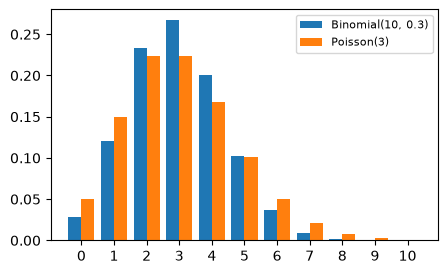

In [2]:
def discrete_shapes():
    k = np.arange(0, 11)
    binom = np.array([math.comb(10, i) * 0.3 ** i * 0.7 ** (10 - i) for i in k])
    pois = np.array([3 ** i * math.exp(-3) / math.factorial(i) for i in k])
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(k - 0.2, binom, width=0.4, label="Binomial(10, 0.3)")
    ax.bar(k + 0.2, pois, width=0.4, label="Poisson(3)")
    ax.set_xticks(k)
    ax.legend(fontsize=8)


discrete_shapes()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q9](#q9), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 2: Continuous distributions and the normal curve

*Level: Basics*

Heights, temperatures and measurement errors can take any value, so we describe them with a **density curve** (PDF). Probability = **area** under the curve; the total area is 1.




- **Uniform**: flat — every value in [a, b] equally likely.
- **Exponential**: waiting times between random events: P(wait ≤ t) = 1 − e^(−λt).
- **Normal** (Gaussian) N(μ, σ): the bell curve, centred at μ with spread σ.



The **68–95–99.7 rule**: about 68% of a normal population lies within 1σ of the mean, 95% within 2σ, 99.7% within 3σ. A **z-score** z = (x − μ)/σ says how many σ's from the mean a value is.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

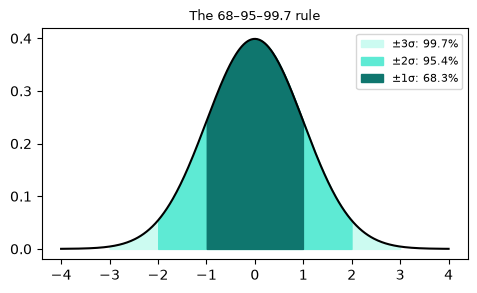

In [3]:
def normal_areas():
    x = np.linspace(-4, 4, 400)
    pdf = np.exp(-x ** 2 / 2) / np.sqrt(2 * np.pi)
    fig, ax = plt.subplots(figsize=(5.5, 3))
    ax.plot(x, pdf, color="black")
    for k, colour in [(3, "#ccfbf1"), (2, "#5eead4"), (1, "#0f766e")]:
        mask = np.abs(x) <= k
        share = math.erf(k / math.sqrt(2))
        ax.fill_between(x[mask], pdf[mask], color=colour, label=f"±{k}σ: {share:.1%}")
    ax.legend(fontsize=8)
    ax.set_title("The 68–95–99.7 rule", fontsize=9)


normal_areas()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q10](#q10), [Q11](#q11), [Q5](#q5), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 3: PMF, PDF and CDF

*Level: Basics*

| Name | For | Gives |
| --- | --- | --- |
| PMF | countable values (a die) | the probability of each value |
| PDF | continuous values (height) | density: probability is the **area** |
| CDF | both | P(X ≤ x): always rises from 0 to 1 |



#### A die



PMF: each value has 1/6. CDF at 4: P(X ≤ 4) = 4/6.



#### Two facts about density that surprise people



- **A density can be above 1.** A uniform distribution on [0, 0.5] has height 2, and the area is still 0.5 × 2 = 1.
- **Exactly one value has probability 0.** P(height = exactly 170.000…) = 0, as a line has no area. Only ranges have probability.



P(a ≤ X ≤ b) = CDF(b) − CDF(a).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

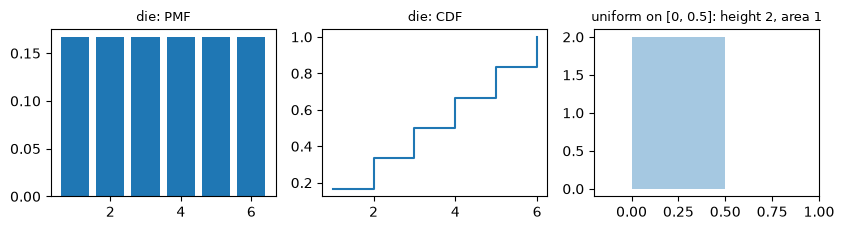

In [4]:
def pmf_pdf_cdf():
    values = np.arange(1, 7)
    pmf = np.full(6, 1 / 6)
    cdf = pmf.cumsum()
    at_four = cdf[3]
    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.4))
    axes[0].bar(values, pmf)
    axes[0].set_title("die: PMF", fontsize=9)
    axes[1].step(values, cdf, where="post")
    axes[1].set_title("die: CDF", fontsize=9)
    axes[2].fill_between([0, 0.5], [2, 2], alpha=0.4)
    axes[2].set_xlim(-0.2, 1)
    axes[2].set_title("uniform on [0, 0.5]: height 2, area 1", fontsize=9)
    fig.tight_layout()


pmf_pdf_cdf()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 4: Why the normal curve is everywhere: the central limit theorem

*Level: Core*

Add up many independent random things and the total's distribution becomes bell-shaped — whatever the shape of each piece. One die is flat; the sum of two is a triangle; three or more already looks like a bell. This is the **central limit theorem**.



That's why measurement errors, test scores and averages of samples are approximately normal, and why confidence intervals use 1.96 (the 95% point of the normal curve). Adding random variables **convolves** their distributions — `np.convolve`.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

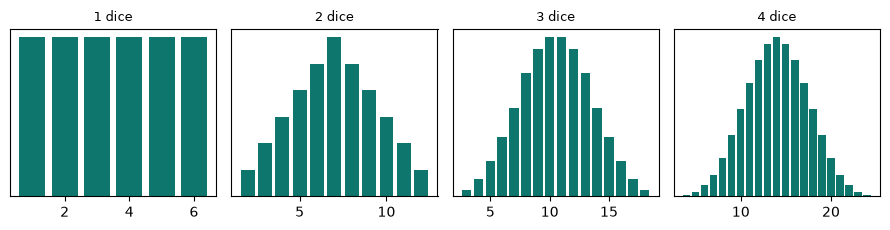

In [5]:
def clt_demo():
    die = np.full(6, 1 / 6)
    dist = die
    fig, axes = plt.subplots(1, 4, figsize=(9, 2.4))
    for n, ax in enumerate(axes, start=1):
        ax.bar(np.arange(n, 6 * n + 1), dist, color="#0f766e")
        ax.set_title(f"{n} dice", fontsize=9)
        ax.set_yticks([])
        dist = np.convolve(dist, die)
    fig.tight_layout()


clt_demo()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 5: The binomial, by hand

*Level: Core*

A player makes free throws with probability 0.8. What's the chance of exactly 4 from 5?



1. **One particular order** (hit, hit, hit, hit, miss): 0.8⁴ × 0.2 = 0.08192.
2. **How many orders?** Choose which 4 shots hit: C(5, 4) = 5.
3. **Multiply:** 5 × 0.08192 = **0.4096**.



P(all 5) = 0.8⁵ = 0.3277, so P(at least 4) = 0.4096 + 0.3277 = 0.7373.



**Shortcuts:** mean = np = 4; variance = np(1 − p) = 0.8.



#### When to use it



Check four conditions: a fixed number of tries, two outcomes, the same chance each time, and independent tries. Drawing cards without putting them back fails the last two.



#### Related distributions



- Many tries with a tiny chance (n large, p small) becomes **Poisson** with λ = np.
- Many tries in general looks **normal**, as the chart shows.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

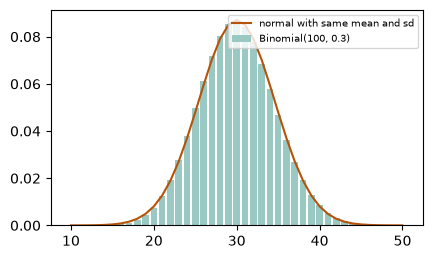

In [6]:
def binomial_by_hand():
    one_order = 0.8 ** 4 * 0.2
    orders = math.comb(5, 4)
    exactly_four = orders * one_order
    all_five = 0.8 ** 5
    n, p = 100, 0.3
    k = np.arange(10, 51)
    pmf = np.array([math.comb(n, int(i)) * p ** int(i) * (1 - p) ** (n - int(i)) for i in k])
    mean, sd = n * p, (n * p * (1 - p)) ** 0.5
    normal = np.exp(-((k - mean) / sd) ** 2 / 2) / (sd * (2 * np.pi) ** 0.5)
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.bar(k, pmf, color="#99c9c2", label="Binomial(100, 0.3)")
    ax.plot(k, normal, color="#b45309", label="normal with same mean and sd")
    ax.legend(fontsize=7)


binomial_by_hand()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q9](#q9), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 6: z-scores and the normal curve, worked

*Level: Core*

Heights have mean 170 cm and standard deviation 10 cm.



| Question | Steps | Answer |
| --- | --- | --- |
| P(height &lt; 185)? | z = (185 − 170)/10 = 1.5; table gives 0.9332 | 93.3% |
| P(160 to 180)? | z from −1 to 1; 0.8413 − 0.1587 | 68.3% |
| P(height &gt; 185)? | 1 − 0.9332 | 6.7% |
| Height of the tallest 10%? | z for 0.90 is 1.2816; 170 + 1.2816 × 10 | 182.8 cm |



#### Comparing different scales



Ana scores 80 in maths (mean 70, sd 10) and 75 in English (mean 60, sd 5). Which is better?



- Maths: z = 1.0
- English: z = 3.0



The lower mark is far more impressive. Standardising puts everything on a common scale.



**Beware:** these answers assume the data is roughly normal. For skewed data such as income, they can be badly wrong. Plot first.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def z_score_steps():
    def cdf(z):
        return 0.5 * (1 + math.erf(z / 2 ** 0.5))

    below_185 = cdf((185 - 170) / 10)
    between = cdf(1) - cdf(-1)
    above_185 = 1 - below_185
    tallest_ten_percent = 170 + 1.2816 * 10
    maths_z, english_z = (80 - 70) / 10, (75 - 60) / 5


z_score_steps()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. cdf() returns 0.9331927987311419
2. cdf() returns 0.8413447460685429
3. cdf() returns 0.15865525393145707
4. z\_score\_steps() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q5](#q5), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 7: Means of samples: the central limit theorem at work

*Level: Core*

Take a value from a skewed distribution, such as a waiting time. Now average 30 such values, and repeat many times. Those averages form a **bell curve** around the true mean, whatever the original shape.



Their spread, the standard error, is **σ / √n**:



| n | 1 | 4 | 25 | 100 |
| --- | --- | --- | --- | --- |
| Spread when σ = 10 | 10 | 5 | 2 | 1 |



So 4× the data halves the uncertainty, and 100× gives one-tenth. Diminishing returns, as the charts show.



#### Why it matters



- **Confidence intervals** and A/B tests rely on it.
- **Mini-batch gradients** are averages. A larger batch gives a less noisy gradient, but quadrupling it only halves the noise, which is why small batches are usually efficient.



**Limits:** rows must be reasonably independent, and very heavy tails need many more samples.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

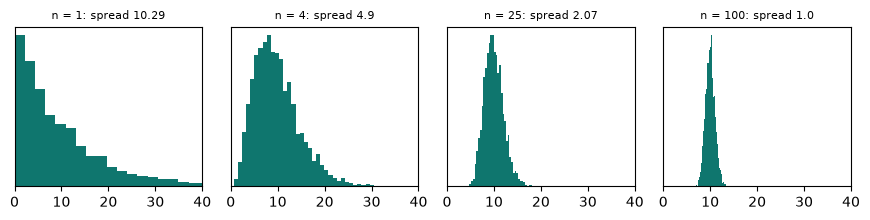

In [8]:
def standard_error_demo():
    r = np.random.default_rng(0)
    sizes = [1, 4, 25, 100]
    fig, axes = plt.subplots(1, 4, figsize=(8.8, 2.3), sharex=True)
    measured = {}
    for ax, n in zip(axes, sizes):
        means = r.exponential(10, (5000, n)).mean(axis=1)
        measured[n] = round(float(means.std()), 2)
        ax.hist(means, bins=40, color="#0f766e")
        ax.set_xlim(0, 40)
        ax.set_yticks([])
        ax.set_title(f"n = {n}: spread {measured[n]}", fontsize=8)
    fig.tight_layout()


standard_error_demo()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 8: Information: entropy, cross-entropy, KL

*Level: Advanced*

**Entropy** H(p) = −Σ p log₂ p measures uncertainty in bits. A fair coin: 1 bit. A certain outcome: 0 bits. Four equal options: 2 bits.



**Cross-entropy** H(p, q) = −Σ p log q measures how well a model's prediction q matches the truth p. If the true class is "cat" (p = [1, 0, 0]) and the model says q = [0.7, 0.2, 0.1], the loss is −log 0.7. **This is the loss function of almost every classifier**, including large language models predicting the next word.



**KL divergence** D(p‖q) = H(p, q) − H(p) is the extra cost of using q instead of p; it's 0 only when they match. Decision trees choose splits by **information gain** (entropy drop) or **Gini impurity**.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

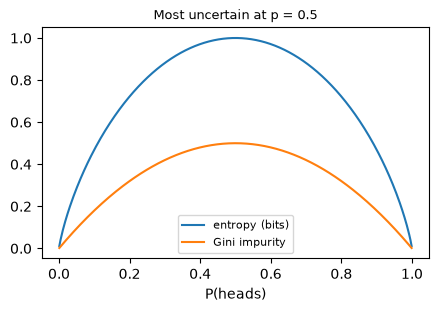

In [9]:
def entropy_curve():
    p = np.linspace(0.001, 0.999, 300)
    H = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
    gini = 1 - p ** 2 - (1 - p) ** 2
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(p, H, label="entropy (bits)")
    ax.plot(p, gini, label="Gini impurity")
    ax.set_xlabel("P(heads)")
    ax.legend(fontsize=8)
    ax.set_title("Most uncertain at p = 0.5", fontsize=9)


entropy_curve()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q15](#q15), [Q8](#q8), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 9: From scores to probabilities to a loss: softmax, log-loss, likelihood

*Level: Advanced*

A classifier first produces raw scores (logits). **Softmax** turns them into probabilities: exponentiate, then divide by the total (subtract the max first so huge scores don't overflow). For two classes, softmax reduces to the sigmoid.



The **log-loss** (binary cross-entropy) −[y log p + (1 − y) log(1 − p)] punishes confident wrong answers enormously: predicting 0.01 for a true 1 costs −log 0.01 ≈ 4.6.



Where do these losses come from? **Maximum likelihood**: choose the parameters that make the observed data most probable. Maximising the log-likelihood of a Bernoulli model *is* minimising log-loss; for a normal model it *is* minimising squared error. That's the bridge from probability to machine learning.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

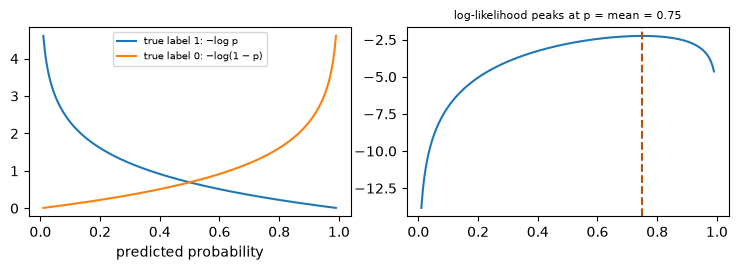

In [10]:
def log_loss_curve():
    p = np.linspace(0.01, 0.99, 200)
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.8))
    left.plot(p, -np.log(p), label="true label 1: −log p")
    left.plot(p, -np.log(1 - p), label="true label 0: −log(1 − p)")
    left.set_xlabel("predicted probability")
    left.legend(fontsize=7)
    data = [1, 0, 1, 1]
    ll = 3 * np.log(p) + np.log(1 - p)
    right.plot(p, ll)
    right.axvline(np.mean(data), color="#b45309", linestyle="--")
    right.set_title("log-likelihood peaks at p = mean = 0.75", fontsize=8)
    fig.tight_layout()


log_loss_curve()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17), [Q18](#q18), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 10: Entropy and KL divergence by hand

*Level: Advanced*

#### Entropy



P = (0.5, 0.25, 0.25).



H = −0.5·log₂0.5 − 0.25·log₂0.25 − 0.25·log₂0.25 = 0.5 + 0.5 + 0.5 = **1.5 bits**.



**Why bits?** Ask "is it A?" (1 question, half the time), then "is it B?" (2 questions otherwise): an average of 1.5 yes/no questions. A heavily biased coin (0.9, 0.1) has only 0.469 bits: it's rarely surprising.



#### Cross-entropy



Reality P = (0.5, 0.25, 0.25), but you believe Q = (0.25, 0.5, 0.25).



H(P, Q) = −0.5·log₂0.25 − 0.25·log₂0.5 − 0.25·log₂0.25 = 1 + 0.25 + 0.5 = **1.75 bits**. Using a wrong belief costs extra.



#### KL divergence



The extra cost: 1.75 − 1.5 = **0.25 bits**.



**It isn't a true distance,** since direction matters. P = (0.9, 0.1) and Q = (0.5, 0.5) give KL(P‖Q) = 0.531, but KL(Q‖P) = 0.737.



Training a classifier minimises cross-entropy. As H(P) is fixed by the data, that also minimises KL: the predictions move towards the truth.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [11]:
def information_by_hand():
    def entropy(p):
        return -sum(a * math.log2(a) for a in p if a > 0)

    def cross(p, q):
        return -sum(a * math.log2(b) for a, b in zip(p, q) if a > 0)

    p, q = [0.5, 0.25, 0.25], [0.25, 0.5, 0.25]
    h = entropy(p)
    ce = cross(p, q)
    kl = ce - h
    forward = cross([0.9, 0.1], [0.5, 0.5]) - entropy([0.9, 0.1])
    backward = cross([0.5, 0.5], [0.9, 0.1]) - entropy([0.5, 0.5])


information_by_hand()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. entropy() returns 1.5
2. cross() returns 1.75
3. cross() returns 1.0
4. entropy() returns 0.4689955935892812
5. cross() returns 1.736965594166206
6. entropy() returns 1.0
7. information\_by\_hand() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q15](#q15), [Q8](#q8), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 11: Maximum likelihood by hand

*Level: Advanced*

A coin lands H, H, T, H. What p best explains this?



#### Step 1: write the likelihood



L(p) = p·p·(1 − p)·p = p³(1 − p).



| p | 0.25 | 0.5 | 0.75 | 0.9 |
| --- | --- | --- | --- | --- |
| L(p) | 0.0117 | 0.0625 | **0.1055** | 0.0729 |



#### Step 2: take logs, which turn products into sums



ln L = 3 ln p + ln(1 − p).



#### Step 3: set the derivative to zero



3/p − 1/(1 − p) = 0, so 3(1 − p) = p and **p = 3/4**. It's simply the share of heads.



#### The link to loss functions



- Bernoulli likelihood → **log-loss**
- Normal likelihood → **squared error**, and the best μ is the mean
- Categorical likelihood → **cross-entropy**



#### Too little data



After H, H, H the estimate is p = 1: "tails is impossible". Add one imaginary head and one imaginary tail (Laplace smoothing): (3 + 1) / (3 + 2) = 0.8. That's the same trick used in Naive Bayes, and it behaves like a prior.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

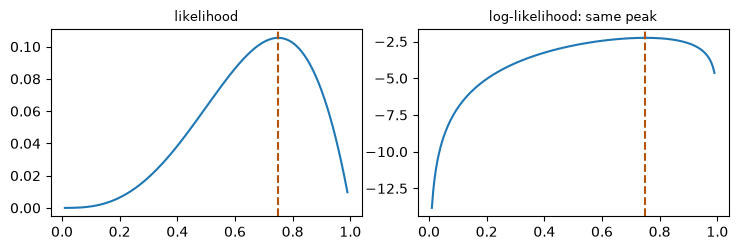

In [12]:
def coin_likelihood():
    p = np.linspace(0.01, 0.99, 197)
    likelihood = p ** 3 * (1 - p)
    log_likelihood = 3 * np.log(p) + np.log(1 - p)
    best = p[likelihood.argmax()]
    same_best = p[log_likelihood.argmax()]
    smoothed = (3 + 1) / (3 + 2)
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.6))
    left.plot(p, likelihood)
    left.axvline(best, ls="--", color="#b45309")
    left.set_title("likelihood", fontsize=9)
    right.plot(p, log_likelihood)
    right.axvline(same_best, ls="--", color="#b45309")
    right.set_title("log-likelihood: same peak", fontsize=9)
    fig.tight_layout()


coin_likelihood()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q19](#q19), [Q17](#q17), [Q16](#q16). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Bernoulli Mean and Variance

🟢 Warm-up · *One yes/no trial*

X is 1 with probability p, else 0. Return (E[X], Var(X)), rounded to 4 decimals.

**Examples**

- `p = 0.3` → `(0.3, 0.21)`
- `p = 0.5` → `(0.5, 0.25)`
- `p = 1.0` → `(1.0, 0.0)`

In [ ]:
def bernoulli(p):
    """
    X is 1 with probability p, else 0. Return (E[X], Var(X)), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bernoulli, [
    ((0.3,), (0.3, 0.21)),
    ((0.5,), (0.5, 0.25)),
    ((1.0,), (1.0, 0.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Use the definitions over the two outcomes 0 and 1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formulas: E = p, Var = p(1 − p).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Use the definitions over the two outcomes 0 and 1.

```python
def bernoulli(p):
    outcomes = [(0, 1 - p), (1, p)]
    mean = sum(x * q for x, q in outcomes)
    var = sum((x - mean) ** 2 * q for x, q in outcomes)
    return (round(mean, 4), round(var, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formulas: E = p, Var = p(1 − p).

```python
def bernoulli(p):
    return (round(p, 4), round(p * (1 - p), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Use the definitions over the two outcomes 0 and 1. That costs O(1) time and O(1) space."

"I can do better: Formulas: E = p, Var = p(1 − p). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/bernoulli-mean-and-variance)

<a id="q2"></a>
### Q2. Poisson Probability

🟢 Warm-up · *Counts of rare events*

Events happen on average lam times per hour. Return P(exactly k events in an hour), rounded to 4 decimals.

**Examples**

- `lam = 3, k = 2` → `0.224`
- `lam = 1, k = 0` → `0.3679`
- `lam = 2, k = 4` → `0.0902`

In [ ]:
def poisson(lam, k):
    """
    Events happen on average lam times per hour. Return P(exactly k events in an
    hour), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(poisson, [
    ((3, 2), 0.224),
    ((1, 0), 0.3679),
    ((2, 4), 0.0902),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build the term step by step: start at e^(−λ) and multiply by λ/i for i = 1 … k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula λᵏe^(−λ)/k!.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Build the term step by step: start at e^(−λ) and multiply by λ/i for i = 1 … k.

```python
def poisson(lam, k):
    term = math.exp(-lam)
    for i in range(1, k + 1):
        term *= lam / i
    return round(term, 4)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula λᵏe^(−λ)/k!.

```python
def poisson(lam, k):
    return round(lam ** k * math.exp(-lam) / math.factorial(k), 4)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build the term step by step: start at e^(−λ) and multiply by λ/i for i = 1 … k. That costs O(k) time and O(1) space."

"I can do better: Formula λᵏe^(−λ)/k!. That's O(k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/poisson-probability)

<a id="q3"></a>
### Q3. Uniform Distribution

🟢 Warm-up · *Every value equally likely*

X is uniform on [lo, hi]. Return P(a ≤ X ≤ b), rounded to 4 decimals.

**Examples**

- `lo = 0, hi = 10, a = 2, b = 5` → `0.3`
- `lo = 0, hi = 4, a = 1, b = 3` → `0.5`
- `lo = 0, hi = 4, a = 3, b = 9` → `0.25`

In [ ]:
def uniform(lo, hi, a, b):
    """
    X is uniform on [lo, hi]. Return P(a ≤ X ≤ b), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(uniform, [
    ((0, 10, 2, 5), 0.3),
    ((0, 4, 1, 3), 0.5),
    ((0, 4, 3, 9), 0.25),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Integrate the flat density 1/(hi − lo) numerically over [a, b] ∩ [lo, hi].

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Length of the overlap divided by the total length.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Integrate the flat density 1/(hi − lo) numerically over [a, b] ∩ [lo, hi].

```python
def uniform(lo, hi, a, b):
    a, b = max(a, lo), min(b, hi)
    if b <= a:
        return 0.0
    steps = 1000
    dx = (b - a) / steps
    area = 0
    for _ in range(steps):
        area += 1 / (hi - lo) * dx
    return round(area, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Length of the overlap divided by the total length.

```python
def uniform(lo, hi, a, b):
    overlap = max(0, min(b, hi) - max(a, lo))
    return round(overlap / (hi - lo), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Integrate the flat density 1/(hi − lo) numerically over [a, b] ∩ [lo, hi]. That costs O(n) time and O(1) space."

"I can do better: Length of the overlap divided by the total length. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/uniform-distribution)

<a id="q4"></a>
### Q4. Height of the Normal Curve

🟢 Warm-up · *The bell curve's PDF*

Return the normal density f(x) for each x, with mean mu and standard deviation s, rounded to 4 decimals.

**Examples**

- `xs = [0, 1], mu = 0, s = 1` → `[0.3989, 0.242]`
- `xs = [70], mu = 65, s = 5` → `[0.0484]`

In [ ]:
def normal_pdf(xs, mu, s):
    """
    Return the normal density f(x) for each x, with mean mu and standard
    deviation s, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(normal_pdf, [
    (([0, 1], 0, 1), [0.3989, 0.242]),
    (([70], 65, 5), [0.0484]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the formula to each x in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with `np.exp`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Apply the formula to each x in a loop.

```python
def normal_pdf(xs, mu, s):
    out = []
    for x in xs:
        z = (x - mu) / s
        out.append(round(math.exp(-z * z / 2) / (s * math.sqrt(2 * math.pi)), 4))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised with `np.exp`.

```python
def normal_pdf(xs, mu, s):
    z = (np.array(xs, dtype=float) - mu) / s
    return (np.exp(-z ** 2 / 2) / (s * np.sqrt(2 * np.pi))).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the formula to each x in a loop. That costs O(n) time and O(n) space."

"I can do better: Vectorised with `np.exp`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/height-of-the-normal-curve)

<a id="q5"></a>
### Q5. Z-Score to Percentile

🟢 Warm-up · *Standardising*

A score x comes from Normal(mu, s). Return (z-score, percentile) — the percentage of scores below x — rounded to 2 decimals.

**Examples**

- `x = 80, mu = 70, s = 10` → `(1.0, 84.13)`
- `x = 70, mu = 70, s = 10` → `(0.0, 50.0)`
- `x = 55, mu = 70, s = 10` → `(-1.5, 6.68)`

In [ ]:
def percentile(x, mu, s):
    """
    A score x comes from Normal(mu, s). Return (z-score, percentile) — the
    percentage of scores below x — rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(percentile, [
    ((80, 70, 10), (1.0, 84.13)),
    ((70, 70, 10), (0.0, 50.0)),
    ((55, 70, 10), (-1.5, 6.68)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

z = (x − μ)/σ, then integrate the standard normal curve up to z.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

z, then the erf formula for the CDF.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** z = (x − μ)/σ, then integrate the standard normal curve up to z.

```python
def percentile(x, mu, s):
    z = (x - mu) / s
    n = 20000
    start = -8.0
    dx = (z - start) / n
    area = 0
    for i in range(n):
        t = start + (i + 0.5) * dx
        area += math.exp(-t * t / 2) / math.sqrt(2 * math.pi) * dx
    return (round(z, 2), round(area * 100, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** z, then the erf formula for the CDF.

```python
def percentile(x, mu, s):
    z = (x - mu) / s
    return (round(z, 2), round(50 * (1 + math.erf(z / math.sqrt(2))), 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: z = (x − μ)/σ, then integrate the standard normal curve up to z. That costs O(n) time and O(1) space."

"I can do better: z, then the erf formula for the CDF. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/z-score-to-percentile)

<a id="q6"></a>
### Q6. Exponential Waiting Time

🟢 Warm-up · *P(wait ≤ t)*

Buses arrive at rate lam per minute (exponential waiting times). Return P(you wait at most t minutes), rounded to 4 decimals.

**Examples**

- `lam = 0.5, t = 2` → `0.6321`
- `lam = 1, t = 3` → `0.9502`
- `lam = 2, t = 0` → `0.0`

In [ ]:
def exp_wait(lam, t):
    """
    Buses arrive at rate lam per minute (exponential waiting times). Return
    P(you wait at most t minutes), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(exp_wait, [
    ((0.5, 2), 0.6321),
    ((1, 3), 0.9502),
    ((2, 0), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Integrate the density λe^(−λx) from 0 to t with thin strips.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Closed form 1 − e^(−λt).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Integrate the density λe^(−λx) from 0 to t with thin strips.

```python
def exp_wait(lam, t):
    n = 10000
    dx = t / n
    area = 0
    for i in range(n):
        x = (i + 0.5) * dx
        area += lam * math.exp(-lam * x) * dx
    return round(area, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Closed form 1 − e^(−λt).

```python
def exp_wait(lam, t):
    return round(1 - math.exp(-lam * t), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Integrate the density λe^(−λx) from 0 to t with thin strips. That costs O(n) time and O(1) space."

"I can do better: Closed form 1 − e^(−λt). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/exponential-waiting-time)

<a id="q7"></a>
### Q7. Distribution of the Sum of Two Dice

🟢 Warm-up · *Convolution*

Return how many of the 36 outcomes give each total 2, 3, …, 12.

**Examples**

- `` → `[1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]`

In [ ]:
def two_dice_counts():
    """
    Return how many of the 36 outcomes give each total 2, 3, …, 12.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_dice_counts, [
    ((), [1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Double loop over both dice, count each total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Adding random variables convolves their distributions: `np.convolve(ones, ones)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Double loop over both dice, count each total.

```python
def two_dice_counts():
    counts = [0] * 11
    for a in range(1, 7):
        for b in range(1, 7):
            counts[a + b - 2] += 1
    return counts
```

**Cost:** O(36) time, O(11) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Adding random variables convolves their distributions: `np.convolve(ones, ones)`.

```python
def two_dice_counts():
    one_die = np.ones(6, dtype=int)
    return np.convolve(one_die, one_die)
```

**Cost:** O(36) time, O(11) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Double loop over both dice, count each total. That costs O(36) time and O(11) space."

"I can do better: Adding random variables convolves their distributions: `np.convolve(ones, ones)`. That's O(36) time and O(11) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/distribution-of-the-sum-of-two-dice)

<a id="q8"></a>
### Q8. Gini Impurity

🟢 Warm-up · *How mixed is a group?*

Return 1 − Σ (share of each class)² for a list of labels, rounded to 4 decimals. 0 = pure.

**Examples**

- `labels = ['a', 'a', 'b', 'b']` → `0.5`
- `labels = ['a', 'a', 'a']` → `0.0`
- `labels = ['a', 'b', 'c']` → `0.6667`

In [ ]:
def gini(labels):
    """
    Return 1 − Σ (share of each class)² for a list of labels, rounded to 4
    decimals. 0 = pure.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gini, [
    ((['a', 'a', 'b', 'b'],), 0.5),
    ((['a', 'a', 'a'],), 0.0),
    ((['a', 'b', 'c'],), 0.6667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count each label in a dictionary, then apply the formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.unique(..., return_counts=True)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Count each label in a dictionary, then apply the formula.

```python
def gini(labels):
    counts = {}
    for lab in labels:
        counts[lab] = counts.get(lab, 0) + 1
    total = 1.0
    for c in counts.values():
        total -= (c / len(labels)) ** 2
    return round(total, 4) + 0.0
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.unique(..., return_counts=True)`.

```python
def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    shares = counts / counts.sum()
    return round(1 - (shares ** 2).sum(), 4) + 0.0
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count each label in a dictionary, then apply the formula. That costs O(n) time and O(k) space."

"I can do better: `np.unique(..., return_counts=True)`. That's O(n log n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/gini-impurity)

<a id="q9"></a>
### Q9. Binomial Probability Table

🟡 Interview standard · *k successes in n tries*

Return P(X = k) for k = 0 … n, where X ~ Binomial(n, p), rounded to 4 decimals.

**Examples**

- `n = 4, p = 0.5` → `[0.0625, 0.25, 0.375, 0.25, 0.0625]`
- `n = 3, p = 0.2` → `[0.512, 0.384, 0.096, 0.008]`

In [ ]:
from itertools import product

def binomial_table(n, p):
    """
    Return P(X = k) for k = 0 … n, where X ~ Binomial(n, p), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(binomial_table, [
    ((4, 0.5), [0.0625, 0.25, 0.375, 0.25, 0.0625]),
    ((3, 0.2), [0.512, 0.384, 0.096, 0.008]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Enumerate all 2ⁿ success/fail sequences, add each one's probability to its k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula C(n, k)·pᵏ(1 − p)ⁿ⁻ᵏ for every k at once with NumPy.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Enumerate all 2ⁿ success/fail sequences, add each one's probability to its k.

```python
def binomial_table(n, p):
    table = [0.0] * (n + 1)
    for seq in product([0, 1], repeat=n):
        k = sum(seq)
        table[k] += p ** k * (1 - p) ** (n - k)
    return [round(x, 4) for x in table]
```

**Cost:** O(2ⁿ · n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula C(n, k)·pᵏ(1 − p)ⁿ⁻ᵏ for every k at once with NumPy.

```python
def binomial_table(n, p):
    k = np.arange(n + 1)
    comb = np.array([math.comb(n, i) for i in k])
    return (comb * p ** k * (1 - p) ** (n - k)).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Enumerate all 2ⁿ success/fail sequences, add each one's probability to its k. That costs O(2ⁿ · n) time and O(n) space."

"I can do better: Formula C(n, k)·pᵏ(1 − p)ⁿ⁻ᵏ for every k at once with NumPy. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/binomial-probability-table)

<a id="q10"></a>
### Q10. Area Under the Normal Curve

🟡 Interview standard · *CDF: P(X ≤ x)*

Return P(X ≤ x) for X ~ Normal(mu, s), rounded to 4 decimals.

**Examples**

- `x = 0, mu = 0, s = 1` → `0.5`
- `x = 1.96, mu = 0, s = 1` → `0.975`
- `x = 80, mu = 70, s = 10` → `0.8413`

In [ ]:
def normal_cdf(x, mu, s):
    """
    Return P(X ≤ x) for X ~ Normal(mu, s), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(normal_cdf, [
    ((0, 0, 1), 0.5),
    ((1.96, 0, 1), 0.975),
    ((80, 70, 10), 0.8413),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up thin strips of the PDF from far left (μ − 8σ) to x.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Closed form with the error function: ½(1 + erf((x − μ)/(σ√2))).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add up thin strips of the PDF from far left (μ − 8σ) to x.

```python
def normal_cdf(x, mu, s):
    start = mu - 8 * s
    n = 20000
    dx = (x - start) / n
    area = 0
    for i in range(n):
        t = start + (i + 0.5) * dx
        area += math.exp(-((t - mu) / s) ** 2 / 2) / (s * math.sqrt(2 * math.pi)) * dx
    return round(area, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Closed form with the error function: ½(1 + erf((x − μ)/(σ√2))).

```python
def normal_cdf(x, mu, s):
    return round(0.5 * (1 + math.erf((x - mu) / (s * math.sqrt(2)))), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up thin strips of the PDF from far left (μ − 8σ) to x. That costs O(n) time and O(1) space."

"I can do better: Closed form with the error function: ½(1 + erf((x − μ)/(σ√2))). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/area-under-the-normal-curve)

<a id="q11"></a>
### Q11. The 68–95–99.7 Rule

🟡 Interview standard · *P(a ≤ X ≤ b)*

Return P(a ≤ X ≤ b) for X ~ Normal(mu, s), rounded to 4 decimals.

**Examples**

- `a = -1, b = 1, mu = 0, s = 1` → `0.6827`
- `a = -2, b = 2, mu = 0, s = 1` → `0.9545`
- `a = 85, b = 110, mu = 100, s = 15` → `0.5889`

In [ ]:
def normal_between(a, b, mu, s):
    """
    Return P(a ≤ X ≤ b) for X ~ Normal(mu, s), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(normal_between, [
    ((-1, 1, 0, 1), 0.6827),
    ((-2, 2, 0, 1), 0.9545),
    ((85, 110, 100, 15), 0.5889),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Integrate the PDF from a to b with thin strips.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

CDF(b) − CDF(a) using erf.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Integrate the PDF from a to b with thin strips.

```python
def normal_between(a, b, mu, s):
    n = 20000
    dx = (b - a) / n
    area = 0
    for i in range(n):
        t = a + (i + 0.5) * dx
        area += math.exp(-((t - mu) / s) ** 2 / 2) / (s * math.sqrt(2 * math.pi)) * dx
    return round(area, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** CDF(b) − CDF(a) using erf.

```python
def normal_between(a, b, mu, s):
    cdf = lambda x: 0.5 * (1 + math.erf((x - mu) / (s * math.sqrt(2))))
    return round(cdf(b) - cdf(a), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Integrate the PDF from a to b with thin strips. That costs O(n) time and O(1) space."

"I can do better: CDF(b) − CDF(a) using erf. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/the-68-95-99-7-rule)

<a id="q12"></a>
### Q12. Sum of Three Dice

🟡 Interview standard · *Towards the bell curve*

Return P(three dice total exactly k), rounded to 4 decimals.

**Examples**

- `k = 10` → `0.125`
- `k = 3` → `0.0046`
- `k = 19` → `0.0`

In [ ]:
def three_dice(k):
    """
    Return P(three dice total exactly k), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(three_dice, [
    ((10,), 0.125),
    ((3,), 0.0046),
    ((19,), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Triple loop over all 216 outcomes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Convolve the single-die distribution with itself twice.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Triple loop over all 216 outcomes.

```python
def three_dice(k):
    hits = 0
    for a in range(1, 7):
        for b in range(1, 7):
            for c in range(1, 7):
                if a + b + c == k:
                    hits += 1
    return round(hits / 216, 4)
```

**Cost:** O(216) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Convolve the single-die distribution with itself twice.

```python
def three_dice(k):
    d = np.full(6, 1 / 6)
    dist = np.convolve(np.convolve(d, d), d)
    return round(dist[k - 3], 4) if 3 <= k <= 18 else 0.0
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Triple loop over all 216 outcomes. That costs O(216) time and O(1) space."

"I can do better: Convolve the single-die distribution with itself twice. That's O(n²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/sum-of-three-dice)

<a id="q13"></a>
### Q13. Entropy

🟡 Interview standard · *Average surprise in bits*

Return the entropy H(p) = −Σ p log₂ p of a probability distribution (0·log 0 counts as 0), rounded to 4 decimals.

**Examples**

- `p = [0.5, 0.5]` → `1.0`
- `p = [1, 0]` → `0.0`
- `p = [0.25, 0.25, 0.25, 0.25]` → `2.0`

In [ ]:
def entropy(p):
    """
    Return the entropy H(p) = −Σ p log₂ p of a probability distribution (0·log 0
    counts as 0), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(entropy, [
    (([0.5, 0.5],), 1.0),
    (([1, 0],), 0.0),
    (([0.25, 0.25, 0.25, 0.25],), 2.0),
    (([0.7, 0.2, 0.1],), 1.1568),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop, skipping zeros.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Mask the zeros, then `-(p * np.log2(p)).sum()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop, skipping zeros.

```python
def entropy(p):
    h = 0
    for x in p:
        if x > 0:
            h -= x * math.log2(x)
    return round(h, 4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Mask the zeros, then `-(p * np.log2(p)).sum()`.

```python
def entropy(p):
    p = np.array(p, dtype=float)
    p = p[p > 0]
    return round(-(p * np.log2(p)).sum(), 4) + 0.0
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop, skipping zeros. That costs O(n) time and O(1) space."

"I can do better: Mask the zeros, then `-(p * np.log2(p)).sum()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/entropy)

<a id="q14"></a>
### Q14. Cross-Entropy

🟡 Interview standard · *How well q predicts p*

Return H(p, q) = −Σ p log₂ q (skip terms where p = 0), rounded to 4 decimals. p = true distribution, q = model's prediction.

**Examples**

- `p = [1, 0, 0], q = [0.7, 0.2, 0.1]` → `0.5146`
- `p = [0.5, 0.5], q = [0.5, 0.5]` → `1.0`
- `p = [0, 1], q = [0.9, 0.1]` → `3.3219`

In [ ]:
def cross_entropy(p, q):
    """
    Return H(p, q) = −Σ p log₂ q (skip terms where p = 0), rounded to 4
    decimals. p = true distribution, q = model's prediction.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cross_entropy, [
    (([1, 0, 0], [0.7, 0.2, 0.1]), 0.5146),
    (([0.5, 0.5], [0.5, 0.5]), 1.0),
    (([0, 1], [0.9, 0.1]), 3.3219),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over the pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with a mask on p &gt; 0.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop over the pairs.

```python
def cross_entropy(p, q):
    h = 0
    for a, b in zip(p, q):
        if a > 0:
            h -= a * math.log2(b)
    return round(h, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised with a mask on p &gt; 0.

```python
def cross_entropy(p, q):
    p, q = np.array(p, dtype=float), np.array(q, dtype=float)
    m = p > 0
    return round(-(p[m] * np.log2(q[m])).sum(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over the pairs. That costs O(n) time and O(1) space."

"I can do better: Vectorised with a mask on p &gt; 0. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/cross-entropy)

<a id="q15"></a>
### Q15. KL Divergence

🟡 Interview standard · *Extra bits from using the wrong distribution*

Return D\_KL(p ‖ q) = Σ p log₂(p/q) (skip p = 0), rounded to 4 decimals.

**Examples**

- `p = [0.5, 0.5], q = [0.9, 0.1]` → `0.737`
- `p = [0.2, 0.8], q = [0.2, 0.8]` → `0.0`
- `p = [0.7, 0.2, 0.1], q = [0.3333333333333333, 0.3333333333333333, 0.3333333333333333]` → `0.4282`

In [ ]:
def kl(p, q):
    """
    Return D_KL(p ‖ q) = Σ p log₂(p/q) (skip p = 0), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(kl, [
    (([0.5, 0.5], [0.9, 0.1]), 0.737),
    (([0.2, 0.8], [0.2, 0.8]), 0.0),
    (([0.7, 0.2, 0.1], [0.3333333333333333, 0.3333333333333333, 0.3333333333333333]), 0.4282),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over the pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Identity: KL = cross-entropy − entropy; or vectorised directly.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop over the pairs.

```python
def kl(p, q):
    d = 0
    for a, b in zip(p, q):
        if a > 0:
            d += a * math.log2(a / b)
    return round(d, 4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Identity: KL = cross-entropy − entropy; or vectorised directly.

```python
def kl(p, q):
    p, q = np.array(p, dtype=float), np.array(q, dtype=float)
    m = p > 0
    return round((p[m] * np.log2(p[m] / q[m])).sum(), 4) + 0.0
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over the pairs. That costs O(n) time and O(1) space."

"I can do better: Identity: KL = cross-entropy − entropy; or vectorised directly. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/kl-divergence)

<a id="q16"></a>
### Q16. Softmax

🟡 Interview standard · *Scores → probabilities*

Turn raw scores into probabilities that sum to 1, rounded to 4 decimals. Must not overflow for large scores.

**Examples**

- `z = [2, 1, 0]` → `[0.6652, 0.2447, 0.09]`
- `z = [1, 1]` → `[0.5, 0.5]`
- `z = [1000, 1000, 999]` → `[0.4223, 0.4223, 0.1554]`

In [ ]:
def softmax(z):
    """
    Turn raw scores into probabilities that sum to 1, rounded to 4 decimals.
    Must not overflow for large scores.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(softmax, [
    (([2, 1, 0],), [0.6652, 0.2447, 0.09]),
    (([1, 1],), [0.5, 0.5]),
    (([1000, 1000, 999],), [0.4223, 0.4223, 0.1554]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Subtract the max (prevents overflow), exponentiate each in a loop, divide by the total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `e = np.exp(z - z.max()); e / e.sum()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Subtract the max (prevents overflow), exponentiate each in a loop, divide by the total.

```python
def softmax(z):
    top = max(z)
    exps = [math.exp(v - top) for v in z]
    total = sum(exps)
    return [round(e / total, 4) for e in exps]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised: `e = np.exp(z - z.max()); e / e.sum()`.

```python
def softmax(z):
    z = np.array(z, dtype=float)
    e = np.exp(z - z.max())
    return (e / e.sum()).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Subtract the max (prevents overflow), exponentiate each in a loop, divide by the total. That costs O(n) time and O(n) space."

"I can do better: Vectorised: `e = np.exp(z - z.max()); e / e.sum()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/softmax)

<a id="q17"></a>
### Q17. Binary Log-Loss

🟡 Interview standard · *The loss of logistic regression*

Return the average binary cross-entropy (natural log) of predicted probabilities p for labels y, rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1], p = [0.9, 0.1, 0.8]` → `0.1446`
- `y = [1, 0], p = [0.5, 0.5]` → `0.6931`

In [ ]:
def log_loss(y, p):
    """
    Return the average binary cross-entropy (natural log) of predicted
    probabilities p for labels y, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(log_loss, [
    (([1, 0, 1], [0.9, 0.1, 0.8]), 0.1446),
    (([1, 0], [0.5, 0.5]), 0.6931),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each example: −log p if y = 1, else −log(1 − p); average.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised formula −mean(y log p + (1 − y) log(1 − p)).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** For each example: −log p if y = 1, else −log(1 − p); average.

```python
def log_loss(y, p):
    total = 0
    for label, prob in zip(y, p):
        if label == 1:
            total += -math.log(prob)
        else:
            total += -math.log(1 - prob)
    return round(total / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised formula −mean(y log p + (1 − y) log(1 − p)).

```python
def log_loss(y, p):
    y, p = np.array(y, dtype=float), np.array(p, dtype=float)
    return round(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each example: −log p if y = 1, else −log(1 − p); average. That costs O(n) time and O(1) space."

"I can do better: Vectorised formula −mean(y log p + (1 − y) log(1 − p)). That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/binary-log-loss)

<a id="q18"></a>
### Q18. Maximum Likelihood for a Coin

🟡 Interview standard · *Best p for the data*

Given coin results (1 = heads), return the p that makes the data most likely, rounded to 4 decimals.

**Examples**

- `data = [1, 0, 1, 1]` → `0.75`
- `data = [0, 0, 0, 1, 1]` → `0.4`

In [ ]:
def coin_mle(data):
    """
    Given coin results (1 = heads), return the p that makes the data most
    likely, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(coin_mle, [
    (([1, 0, 1, 1],), 0.75),
    (([0, 0, 0, 1, 1],), 0.4),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Try every p on a fine grid and keep the one with the highest log-likelihood.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Calculus: setting d/dp of the log-likelihood to 0 gives p̂ = mean of the data.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Try every p on a fine grid and keep the one with the highest log-likelihood.

```python
def coin_mle(data):
    heads = sum(data)
    tails = len(data) - heads
    best_p, best_ll = None, None
    for i in range(1, 1000):
        p = i / 1000
        ll = heads * math.log(p) + tails * math.log(1 - p)
        if best_ll is None or ll > best_ll:
            best_p, best_ll = p, ll
    return round(best_p, 4)
```

**Cost:** O(grid · n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Calculus: setting d/dp of the log-likelihood to 0 gives p̂ = mean of the data.

```python
def coin_mle(data):
    return round(np.mean(data), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Try every p on a fine grid and keep the one with the highest log-likelihood. That costs O(grid · n) time and O(1) space."

"I can do better: Calculus: setting d/dp of the log-likelihood to 0 gives p̂ = mean of the data. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/maximum-likelihood-for-a-coin)

<a id="q19"></a>
### Q19. Log-Likelihood Under a Normal Model

🟡 Interview standard · *Σ log f(xᵢ)*

Return the total log-likelihood (natural log) of the data under Normal(mu, s), rounded to 4 decimals.

**Examples**

- `data = [1, 2, 3], mu = 2, s = 1` → `-3.7568`
- `data = [1, 2, 3], mu = 0, s = 2` → `-6.5863`

In [ ]:
def log_likelihood(data, mu, s):
    """
    Return the total log-likelihood (natural log) of the data under Normal(mu,
    s), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(log_likelihood, [
    (([1, 2, 3], 2, 1), -3.7568),
    (([1, 2, 3], 0, 2), -6.5863),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: log of each density value, add them up.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Simplify the log first: −½log(2πσ²) − (x − μ)²/(2σ²), then sum with NumPy.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: log of each density value, add them up.

```python
def log_likelihood(data, mu, s):
    total = 0
    for x in data:
        density = math.exp(-((x - mu) / s) ** 2 / 2) / (s * math.sqrt(2 * math.pi))
        total += math.log(density)
    return round(total, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Simplify the log first: −½log(2πσ²) − (x − μ)²/(2σ²), then sum with NumPy.

```python
def log_likelihood(data, mu, s):
    x = np.array(data, dtype=float)
    return round((-0.5 * np.log(2 * np.pi * s ** 2) - (x - mu) ** 2 / (2 * s ** 2)).sum(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: log of each density value, add them up. That costs O(n) time and O(1) space."

"I can do better: Simplify the log first: −½log(2πσ²) − (x − μ)²/(2σ²), then sum with NumPy. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/log-likelihood-under-a-normal-model)

<a id="q20"></a>
### Q20. Information Gain of a Split

🔴 Stretch · *How decision trees choose questions*

Return entropy(parent) − weighted average entropy of the two children, rounded to 4 decimals.

**Examples**

- `parent = ['y', 'y', 'y', 'n', 'n', 'n'], left = ['y', 'y', 'y', 'n'], right = ['n', 'n']` → `0.4591`
- `parent = ['y', 'n', 'y', 'n'], left = ['y', 'n'], right = ['y', 'n']` → `0.0`

In [ ]:
def info_gain(parent, left, right):
    """
    Return entropy(parent) − weighted average entropy of the two children,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(info_gain, [
    ((['y', 'y', 'y', 'n', 'n', 'n'], ['y', 'y', 'y', 'n'], ['n', 'n']), 0.4591),
    ((['y', 'n', 'y', 'n'], ['y', 'n'], ['y', 'n']), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Entropy by counting labels in loops, for each group.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A small vectorised entropy helper using `np.unique`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Entropy by counting labels in loops, for each group.

```python
def info_gain(parent, left, right):
    def H(labels):
        counts = {}
        for lab in labels:
            counts[lab] = counts.get(lab, 0) + 1
        h = 0
        for c in counts.values():
            p = c / len(labels)
            h -= p * math.log2(p)
        return h
    n = len(parent)
    children = len(left) / n * H(left) + len(right) / n * H(right)
    return round(H(parent) - children, 4) + 0.0
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** A small vectorised entropy helper using `np.unique`.

```python
def info_gain(parent, left, right):
    def H(labels):
        _, c = np.unique(labels, return_counts=True)
        p = c / c.sum()
        return -(p * np.log2(p)).sum()
    n = len(parent)
    return round(H(parent) - (len(left) * H(left) + len(right) * H(right)) / n, 4) + 0.0
```

**Cost:** O(n log n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Entropy by counting labels in loops, for each group. That costs O(n) time and O(k) space."

"I can do better: A small vectorised entropy helper using `np.unique`. That's O(n log n) time and O(k) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `parent = ['y', 'y', 'y', 'n', 'n', 'n'], left = ['y', 'y', 'y', 'n'], right = ['n', 'n']`

1. H() returns 1.0
2. H() returns 0.8112781244591328
3. H() returns -0.0
4. info\_gain() returns 0.4591

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/distributions/information-gain-of-a-split)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why is the normal distribution so common?</b></summary>

Because of the central limit theorem: anything formed by adding many small independent effects (errors, heights, averages) is approximately normal.

</details>

<details>
<summary><b>2. PDF vs probability?</b></summary>

For continuous variables the PDF is a density, not a probability — it can exceed 1. Probabilities are areas under it: P(a ≤ X ≤ b) = ∫ₐᵇ f.

</details>

<details>
<summary><b>3. What is entropy in simple words?</b></summary>

How unpredictable something is, measured as the average number of yes/no questions needed to identify the outcome.

</details>

<details>
<summary><b>4. Why is cross-entropy used as the classification loss?</b></summary>

It is the negative log-likelihood of the true labels under the model's predicted probabilities, it heavily punishes confident mistakes, and with softmax/sigmoid it gives simple, well-behaved gradients (p − y).

</details>

<details>
<summary><b>5. Why subtract the maximum in softmax?</b></summary>

softmax(z) = softmax(z − c) for any constant c, and subtracting the max keeps every exponent ≤ 0, so e^z never overflows to infinity.

</details>

<details>
<summary><b>6. Gini vs entropy in decision trees?</b></summary>

Both measure how mixed a node is and usually choose similar splits. Gini is slightly faster (no logarithm); entropy relates directly to information gain.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Discrete distributions: Bernoulli, binomial, Poisson
- [ ] I can explain: Continuous distributions and the normal curve
- [ ] I can explain: PMF, PDF and CDF
- [ ] I can explain: Why the normal curve is everywhere: the central limit theorem
- [ ] I can explain: The binomial, by hand
- [ ] I can explain: z-scores and the normal curve, worked
- [ ] I can explain: Means of samples: the central limit theorem at work
- [ ] I can explain: Information: entropy, cross-entropy, KL
- [ ] I can explain: From scores to probabilities to a loss: softmax, log-loss, likelihood
- [ ] I can explain: Entropy and KL divergence by hand
- [ ] I can explain: Maximum likelihood by hand

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Softmax
- [ ] [Q17](#q17) Binary Log-Loss
- [ ] [Q18](#q18) Maximum Likelihood for a Coin
- [ ] [Q19](#q19) Log-Likelihood Under a Normal Model
- [ ] [Q20](#q20) Information Gain of a Split

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.